## Dataset 
Given data set in `digits-dataset.mat` contains $n = 5000$ training examples of handwritten digits. Each training example is a vector in $\mathbb{R}^d$ where $d=400$, resulting from a 20 pixel by 20 pixel grayscale image of the digit. In order words, each pixel is represented by a floating point number indicating the grayscale intensity at that location; the 20 by 20 grid of pixels was "*unrolled*" (i.e. flattened) into a 400-dimensional vector. So, each of these training examples becomes a single row in our data matrix $X$. This gives us a $5000 \times 400$ matrix $X \in \mathbb{R}^{5000 \times 400}$ where every row is a training example for a handwritten digit image.

The second part of the training set is a vector $y$ of dimension 5000, that contains labels for the training set.

Input shape X = (5000, 400)
Output shape y = (5000,)
Unique labels y =  [0 1 2 3 4 5 6 7 8 9]
Plotting 100 digits: 


C:\Users\sahbi\AppData\Local\Temp\ipykernel_25764\3271848871.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


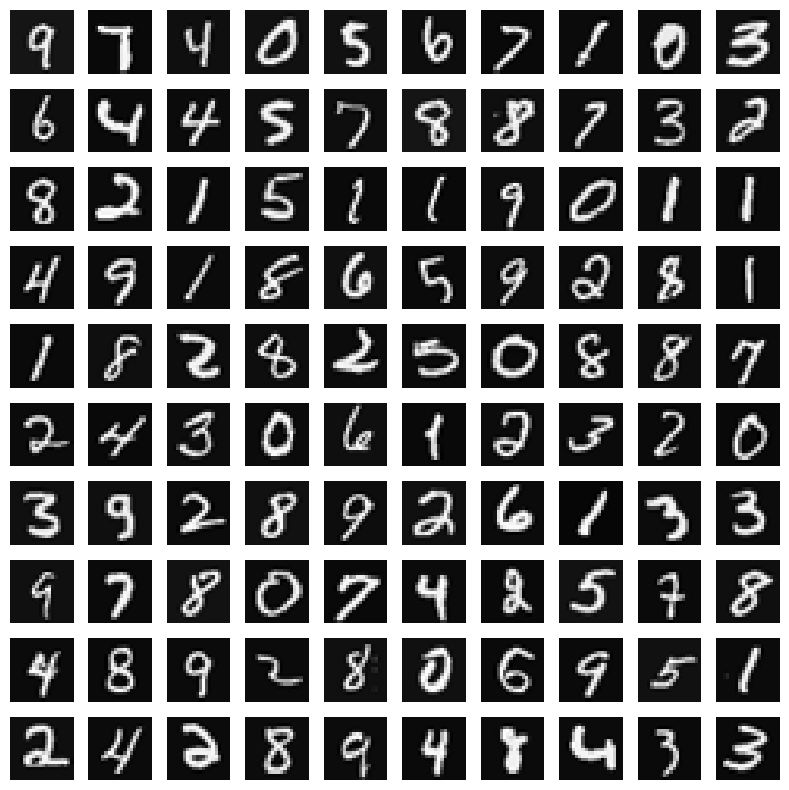

In [2]:
# Load and Visualize 
from scipy.io import loadmat
import matplotlib.pyplot as plt 
import numpy as np


filepath = "datasets/digits-dataset.mat"

mat_data = loadmat(filepath)
X  = mat_data["X"].astype(np.float32)    # X
y  = mat_data["y"].flatten()  # Y 

# Data shape 
print("Input shape X =",X.shape)
print("Output shape y =", y.shape)
print("Unique labels y = ", np.unique(y))

#Visulaize n digits 

def visualize_100_digits(X): 
    ids = np.random.choice(len(X), 100, replace= False)
    images = X[ids].reshape(100, 20, 20)

    print("Plotting 100 digits: ")
    fig, axes = plt.subplots(10, 10,figsize=(8, 8))

    for i in range(10):
        for j in range(10):
            img = images[i*10+j].T
            axes[i][j].imshow( img, cmap='gray' )
            axes[i][j].axis("off")
    plt.tight_layout()
    fig.show()
visualize_100_digits(X)


X_2d shape: (5000, 2)
Explained variance per components =   [0.11060633 0.07975677]
Total kept =  0.1903631
((0.12156862745098039, 0.4666666666666667, 0.7058823529411765), (1.0, 0.4980392156862745, 0.054901960784313725), (0.17254901960784313, 0.6274509803921569, 0.17254901960784313), (0.8392156862745098, 0.15294117647058825, 0.1568627450980392), (0.5803921568627451, 0.403921568627451, 0.7411764705882353), (0.5490196078431373, 0.33725490196078434, 0.29411764705882354), (0.8901960784313725, 0.4666666666666667, 0.7607843137254902), (0.4980392156862745, 0.4980392156862745, 0.4980392156862745), (0.7372549019607844, 0.7411764705882353, 0.13333333333333333), (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))


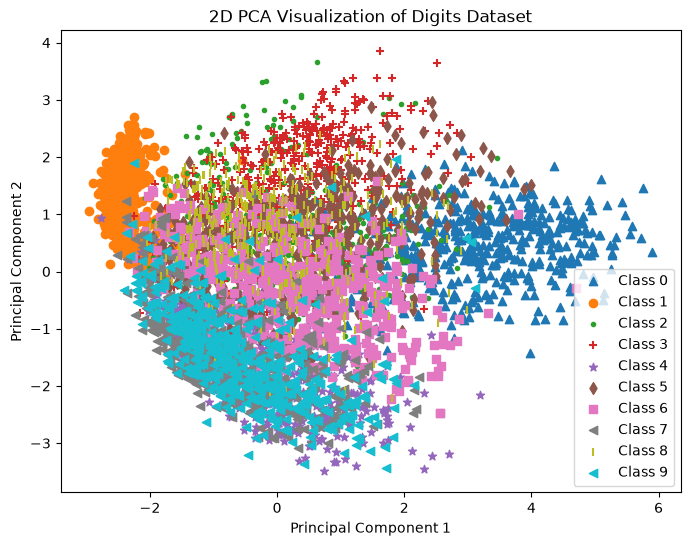

In [3]:
# Visualize using PCA 
from sklearn.decomposition import PCA

pca = PCA(n_components = 2) # Here only for visualization
X_pca = pca.fit_transform(X) # finds two directions in which the 400 pixel values vary the most 
                            # (5000, 2)

print("X_2d shape:", X_pca.shape)
print("Explained variance per components =  ", pca.explained_variance_ratio_)
print("Total kept = ", pca.explained_variance_ratio_.sum())


# Visualize 
fig, ax = plt.subplots(figsize=(8, 6))
markers = ["^", "o", ".", "+", "*", "d", "s", "<", "|", "<"]
colors = plt.cm.tab10.colors # gets 10 colors from the tab10 colormap
classes = np.unique(y) # finds unique classes in dataset (0-9)
print(colors)

for i, cls in enumerate(classes):
    mask = (y == cls) # get indcies matching class
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], marker=markers[i], color=colors[i], label=f"Class {cls}")

ax.set_title("2D PCA Visualization of Digits Dataset")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend()
plt.show()

# Model Train Choise :
1. Out of the training models (MLP, CNN, Tiny ResNet ) : MLP to be used as a baseling , followed by CNN 
2. Assumptions: 
    - For air drawn pattern recognization with the 2d training data set can be tricky as model will not be introduced to it 
    - Thus, MLP need mrore neuron and even more data to covers the maximum edges while CNN has a small window and shared the pattern it learnt(inductive bias), making it requires fewer parameters, may be accurate in detecting unseen shifted data(shifted digits)
3. Approached: 
    - Train MLP and CNN 
    - Compare their computational power, accuracy,  space constraint,  time of execution and first layer weights 
    - Quatize one model based on their comaprision 
    - Inference to esp32
    - Test with raw stroke 
    - Deploy with esp32 camera 


In [ ]:
# MLP Baseline trainig 
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42)
tf.random.set_seed(42)

X = np.clip(X, 0.0, 1.0) # making sure pixel is in between 0 to 1.0 

print("X:", X.shape, "y:", y.shape, "labels:", np.unique(y))


# Test : for final accuracy test 
# validate: check after every epoch, to decide when to stop

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

print("train data length =", len(X_train))
print("val data length   =",  len(X_val))
print("test data length  =", len(X_test))


model = tf.keras.Sequential([
    tf.keras.Input(shape=(400,)),
    tf.keras.layers.Dense(128, activation="relu"), # hidden layer 1 
    tf.keras.layers.Dropout(0.2),   # to stop relying on specific neurons: reduce overfitting 
    tf.keras.layers.Dense(128, activation="relu"),   # hidden layer 2
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels are plain integers 0..9
    metrics=["accuracy"],
)
model.summary()   # expect about 52,600 parameters

X: (5000, 400) y: (5000,) labels: [0 1 2 3 4 5 6 7 8 9]
train data length = 3612
val data length   = 638
test data length  = 750


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        51,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,130 (270.04 KB)

 Trainable params: 69,130 (270.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# MLP Model train 
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
)

Epoch 1/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6739 - loss: 1.1116 - val_accuracy: 0.8793 - val_loss: 0.4604
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8690 - loss: 0.4444 - val_accuracy: 0.8981 - val_loss: 0.3513
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8978 - loss: 0.3396 - val_accuracy: 0.9185 - val_loss: 0.2963
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9239 - loss: 0.2557 - val_accuracy: 0.9295 - val_loss: 0.2620
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9316 - loss: 0.2236 - val_accuracy: 0.9295 - val_loss: 0.2613
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9441 - loss: 0.1895 - val_accuracy: 0.9279 - val_loss: 0.2415
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9529 - loss: 0.1558 - val_accuracy: 0.9310 - val_loss: 0.2442
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9538 - loss: 0.1424 - val_accu

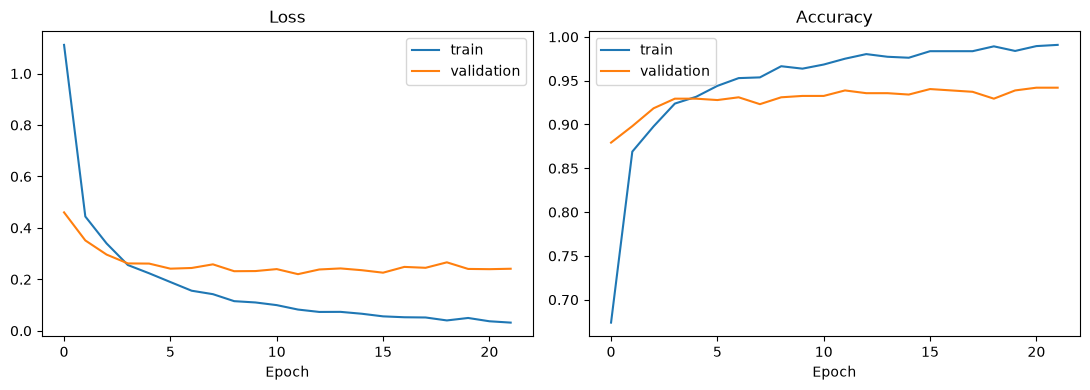

In [6]:
#  Learning plot 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history.history["loss"], label="train")
ax1.plot(history.history["val_loss"], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(history.history["accuracy"], label="train")
ax2.plot(history.history["val_accuracy"], label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig("mlp_curves.png", dpi=150); plt.show()

In [ ]:
# Evaluate 
